<a href="https://colab.research.google.com/github/sonikumari2005/Applied-Predictive-Analysis/blob/main/Wine_Quality_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🍷 Wine Quality Prediction Using Regression and Classification

## 1. Project Introduction

Wine Quality Prediction is a Machine Learning project that predicts wine quality based on its physicochemical properties.

The main objective of this project is to analyze the chemical characteristics of red and white wine and predict their quality scores using Regression and Classification techniques.

## 2. Project Objectives

- Analyze Red Wine and White Wine datasets.
- Perform Exploratory Data Analysis (EDA).
- Conduct statistical analysis.
- Identify important chemical properties affecting wine quality.
- Build Regression models to predict wine quality scores.
- Build Classification models to classify wine quality.
- Compare different Machine Learning algorithms.
- Evaluate model performance using appropriate metrics.

## 3. Dataset

Source: UCI Machine Learning Repository

Dataset: Wine Quality Dataset

## 4. Technologies Used

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## 5. Machine Learning Algorithms

### Regression
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- Support Vector Regression (SVR)

### Classification
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier
- Support Vector Machine (SVM)

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving wine+quality.zip to wine+quality.zip


In [ ]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/wine_data')

print("Dataset extracted successfully")

Dataset extracted successfully


In [ ]:
os.listdir('/content/wine_data')

['winequality.names', 'winequality-white.csv', 'winequality-red.csv']

In [ ]:
red_wine = pd.read_csv('/content/wine_data/winequality-red.csv', sep=';')

white_wine = pd.read_csv('/content/wine_data/winequality-white.csv', sep=';')

print("Red Wine Dataset Loaded Successfully")
print("White Wine Dataset Loaded Successfully")

Red Wine Dataset Loaded Successfully
White Wine Dataset Loaded Successfully


In [ ]:
print("Red Wine Dataset:", red_wine.shape)
print("White Wine Dataset:", white_wine.shape)

Red Wine Dataset: (1599, 12)
White Wine Dataset: (4898, 12)


In [ ]:
red_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [ ]:
white_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [ ]:
red_wine.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [ ]:
white_wine.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7
4897,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6


In [ ]:
print("Red Wine Columns:")
print(red_wine.columns.tolist())

print("\nWhite Wine Columns:")
print(white_wine.columns.tolist())

Red Wine Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

White Wine Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [ ]:
red_wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [ ]:
white_wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [ ]:
red_wine.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [ ]:
white_wine.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [ ]:
print("Red Wine Missing Values:")
print(red_wine.isnull().sum())

print("\nWhite Wine Missing Values:")
print(white_wine.isnull().sum())

Red Wine Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

White Wine Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [ ]:
print("Red Wine Duplicates:", red_wine.duplicated().sum())

print("White Wine Duplicates:", white_wine.duplicated().sum())

Red Wine Duplicates: 0
White Wine Duplicates: 0


In [ ]:
red_wine = red_wine.drop_duplicates()

white_wine = white_wine.drop_duplicates()

print("Duplicate values removed successfully")

Duplicate values removed successfully


In [ ]:
print("Red Wine Dataset Information")
red_wine.info()

print("\nWhite Wine Dataset Information")
white_wine.info()

Red Wine Dataset Information
<class 'pandas.core.frame.DataFrame'>
Index: 1359 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1359 non-null   float64
 1   volatile acidity      1359 non-null   float64
 2   citric acid           1359 non-null   float64
 3   residual sugar        1359 non-null   float64
 4   chlorides             1359 non-null   float64
 5   free sulfur dioxide   1359 non-null   float64
 6   total sulfur dioxide  1359 non-null   float64
 7   density               1359 non-null   float64
 8   pH                    1359 non-null   float64
 9   sulphates             1359 non-null   float64
 10  alcohol               1359 non-null   float64
 11  quality               1359 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 138.0 KB

White Wine Dataset Information
<class 'pandas.core.frame.DataFrame'>
Index: 3961 entries, 0 to 4897
D

In [ ]:
display(red_wine.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000
mean,8.310596,0.529478,0.272333,2.523400,0.088124,15.893304,46.825975,0.996709,3.309787,0.658705,10.432315,5.623252
std,1.736990,0.183031,0.195537,1.352314,0.049377,10.447270,33.408946,0.001869,0.155036,0.170667,1.082065,0.823578
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996700,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.430000,2.600000,0.091000,21.000000,63.000000,0.997820,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [ ]:
display(white_wine.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000
mean,6.839346,0.280538,0.334332,5.914819,0.045905,34.889169,137.193512,0.993790,3.195458,0.490351,10.589358,5.854835
std,0.866860,0.103437,0.122446,4.861646,0.023103,17.210021,43.129065,0.002905,0.151546,0.113523,1.217076,0.890683
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.600000,0.035000,23.000000,106.000000,0.991620,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,4.700000,0.042000,33.000000,133.000000,0.993500,3.180000,0.480000,10.400000,6.000000
75%,7.300000,0.330000,0.390000,8.900000,0.050000,45.000000,166.000000,0.995710,3.290000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [ ]:
print(red_wine.isnull().sum().sum())
print(white_wine.isnull().sum().sum())

0
0


In [ ]:
red_wine['wine_type'] = 'Red'
white_wine['wine_type'] = 'White'

print("Wine type column added successfully")

Wine type column added successfully


In [ ]:
wine_data = pd.concat([red_wine, white_wine], axis=0, ignore_index=True)

print("Combined Dataset Shape:", wine_data.shape)

Combined Dataset Shape: (5320, 13)


In [ ]:
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,Red


In [ ]:
wine_data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000
mean,7.215179,0.344130,0.318494,5.048477,0.056690,30.036654,114.109023,0.994535,3.224664,0.533357,10.549241,5.795677
std,1.319671,0.168248,0.147157,4.500180,0.036863,17.805045,56.774223,0.002966,0.160379,0.149743,1.185933,0.879772
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.240000,1.800000,0.038000,16.000000,74.000000,0.992200,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.300000,0.310000,2.700000,0.047000,28.000000,116.000000,0.994650,3.210000,0.510000,10.400000,6.000000
75%,7.700000,0.410000,0.400000,7.500000,0.066000,41.000000,153.250000,0.996770,3.330000,0.600000,11.400000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [ ]:
wine_data.mean(numeric_only=True)

,0
fixed acidity,7.215179
volatile acidity,0.344130
citric acid,0.318494
residual sugar,5.048477
chlorides,0.056690
free sulfur dioxide,30.036654
total sulfur dioxide,114.109023
density,0.994535
pH,3.224664
sulphates,0.533357


In [ ]:
wine_data.median(numeric_only=True)

,0
fixed acidity,7.00000
volatile acidity,0.30000
citric acid,0.31000
residual sugar,2.70000
chlorides,0.04700
free sulfur dioxide,28.00000
total sulfur dioxide,116.00000
density,0.99465
pH,3.21000
sulphates,0.51000


In [ ]:
wine_data.mode().iloc[0]

,0
fixed acidity,6.8
volatile acidity,0.28
citric acid,0.3
residual sugar,1.6
chlorides,0.036
free sulfur dioxide,6.0
total sulfur dioxide,111.0
density,0.992
pH,3.16
sulphates,0.5


In [ ]:
wine_data.std(numeric_only=True)

,0
fixed acidity,1.319671
volatile acidity,0.168248
citric acid,0.147157
residual sugar,4.500180
chlorides,0.036863
free sulfur dioxide,17.805045
total sulfur dioxide,56.774223
density,0.002966
pH,0.160379
sulphates,0.149743


In [ ]:
wine_data.corr(numeric_only=True)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,0.214752,0.330328,-0.104439,0.288918,-0.281590,-0.327471,0.478180,-0.271182,0.304844,-0.102573,-0.080092
volatile acidity,0.214752,1.000000,-0.384192,-0.163696,0.367626,-0.349039,-0.400716,0.308452,0.246687,0.227772,-0.065411,-0.265205
citric acid,0.330328,-0.384192,1.000000,0.146189,0.055199,0.130849,0.194835,0.094758,-0.344735,0.059183,-0.005496,0.097954
residual sugar,-0.104439,-0.163696,0.146189,1.000000,-0.123094,0.398717,0.487519,0.520930,-0.234522,-0.174717,-0.305242,-0.056830
chlorides,0.288918,0.367626,0.055199,-0.123094,1.000000,-0.186615,-0.269817,0.371867,0.025823,0.405051,-0.269601,-0.202137
free sulfur dioxide,-0.281590,-0.349039,0.130849,0.398717,-0.186615,1.000000,0.720488,0.006166,-0.141747,-0.198244,-0.170012,0.054002
total sulfur dioxide,-0.327471,-0.400716,0.194835,0.487519,-0.269817,0.720488,1.000000,0.006711,-0.222956,-0.275836,-0.249004,-0.050296
density,0.478180,0.308452,0.094758,0.520930,0.371867,0.006166,0.006711,1.000000,0.034273,0.282690,-0.667811,-0.326434
pH,-0.271182,0.246687,-0.344735,-0.234522,0.025823,-0.141747,-0.222956,0.034273,1.000000,0.168150,0.097314,0.039733
sulphates,0.304844,0.227772,0.059183,-0.174717,0.405051,-0.198244,-0.275836,0.282690,0.168150,1.000000,-0.017232,0.041884


In [ ]:
wine_data['quality'].value_counts().sort_index()

,count
quality,
3,30
4,206
5,1752
6,2323
7,856
8,148
9,5


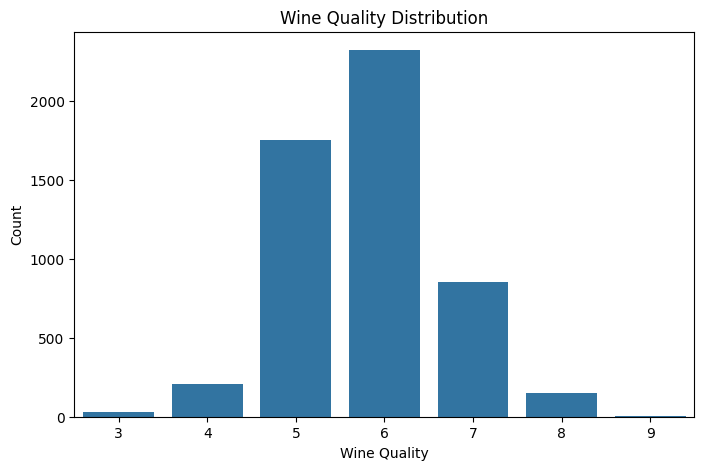

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=wine_data, x='quality')

plt.title('Wine Quality Distribution')
plt.xlabel('Wine Quality')
plt.ylabel('Count')

plt.show()

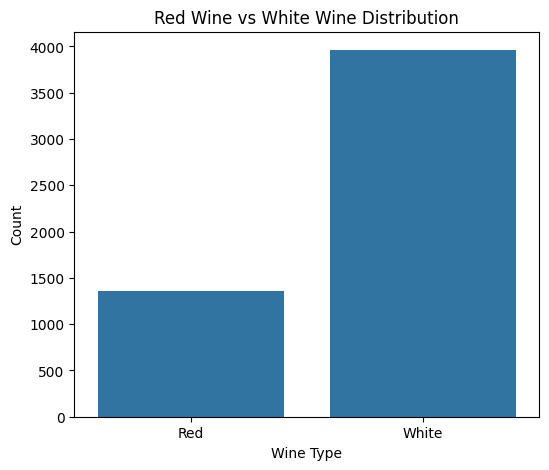

In [ ]:
plt.figure(figsize=(6,5))

sns.countplot(data=wine_data, x='wine_type')

plt.title('Red Wine vs White Wine Distribution')
plt.xlabel('Wine Type')
plt.ylabel('Count')

plt.show()

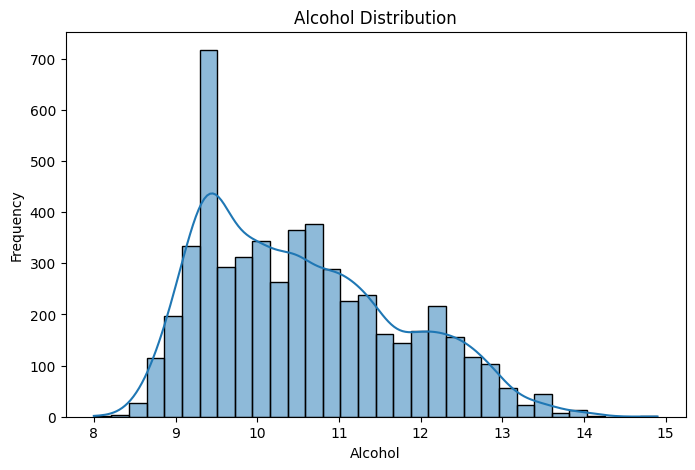

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(data=wine_data, x='alcohol', kde=True)

plt.title('Alcohol Distribution')
plt.xlabel('Alcohol')
plt.ylabel('Frequency')

plt.show()

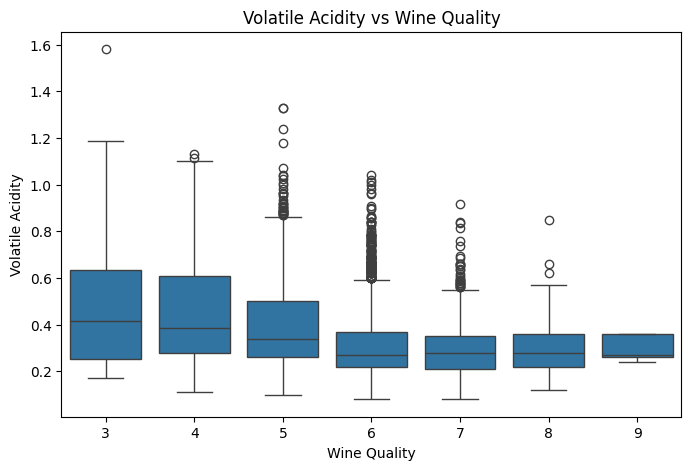

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=wine_data, x='quality', y='volatile acidity')

plt.title('Volatile Acidity vs Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Volatile Acidity')

plt.show()

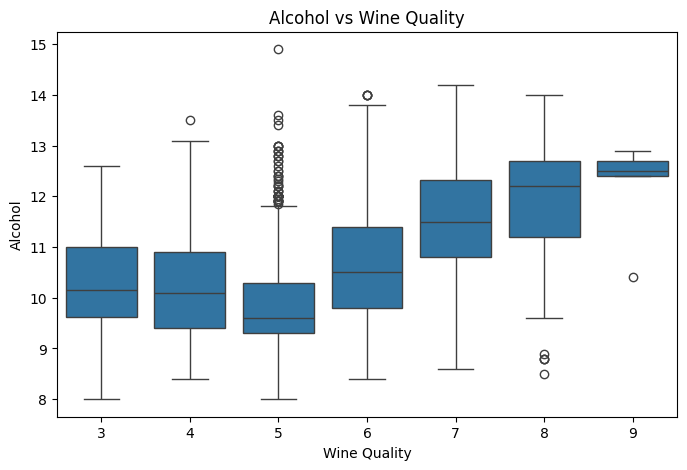

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=wine_data, x='quality', y='alcohol')

plt.title('Alcohol vs Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Alcohol')

plt.show()

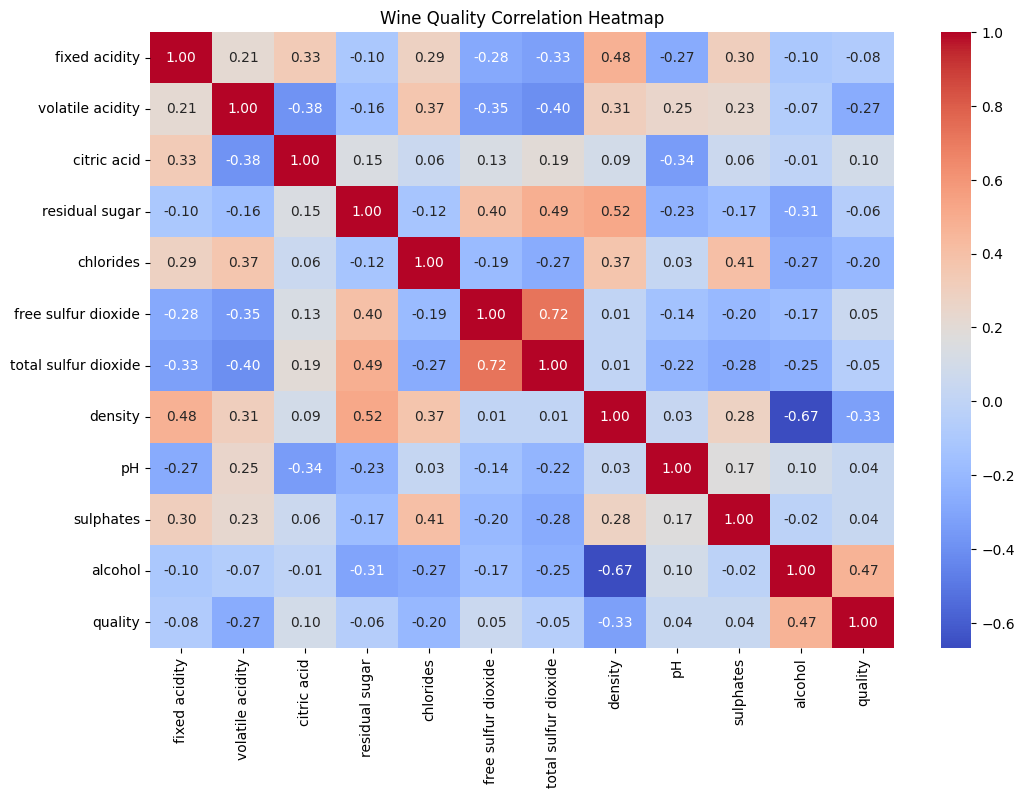

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    wine_data.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Wine Quality Correlation Heatmap')

plt.show()

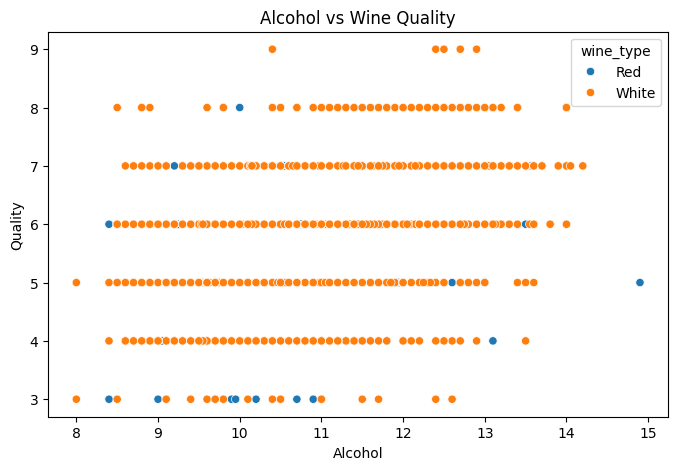

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=wine_data,
    x='alcohol',
    y='quality',
    hue='wine_type'
)

plt.title('Alcohol vs Wine Quality')
plt.xlabel('Alcohol')
plt.ylabel('Quality')

plt.show()

In [ ]:
X = wine_data.drop('quality', axis=1)

y = wine_data['quality']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5320, 12)
Target Shape: (5320,)


In [ ]:
correlation = wine_data.corr(numeric_only=True)

quality_corr = correlation['quality'].sort_values(ascending=False)

print(quality_corr)

quality                 1.000000
alcohol                 0.469422
citric acid             0.097954
free sulfur dioxide     0.054002
sulphates               0.041884
pH                      0.039733
total sulfur dioxide   -0.050296
residual sugar         -0.056830
fixed acidity          -0.080092
chlorides              -0.202137
volatile acidity       -0.265205
density                -0.326434
Name: quality, dtype: float64


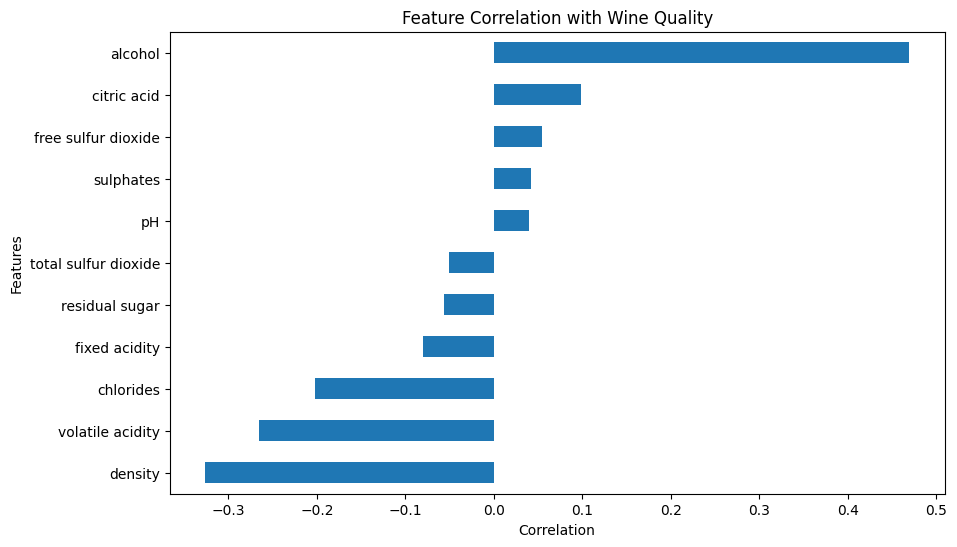

In [ ]:
plt.figure(figsize=(10,6))

quality_corr.drop('quality').sort_values().plot(kind='barh')

plt.title('Feature Correlation with Wine Quality')
plt.xlabel('Correlation')
plt.ylabel('Features')

plt.show()

In [ ]:
selected_features = [
    'alcohol',
    'volatile acidity',
    'sulphates',
    'citric acid',
    'density',
    'chlorides',
    'total sulfur dioxide',
    'fixed acidity',
    'residual sugar',
    'free sulfur dioxide',
    'pH'
]

X = wine_data[selected_features]

print("Selected Features:")
print(X.columns.tolist())

Selected Features:
['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'density', 'chlorides', 'total sulfur dioxide', 'fixed acidity', 'residual sugar', 'free sulfur dioxide', 'pH']


In [ ]:
X = wine_data.drop('quality', axis=1)

y = wine_data['quality']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (5320, 12)
y Shape: (5320,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4256, 12)
Testing Data: (1064, 12)


In [ ]:
wine_data['wine_type'] = wine_data['wine_type'].map({
    'Red': 0,
    'White': 1
})

print(wine_data['wine_type'].value_counts())

wine_type
1    3961
0    1359
Name: count, dtype: int64


In [ ]:
X = wine_data.drop('quality', axis=1)
y = wine_data['quality']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [ ]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

print("Linear Regression Model Trained Successfully")

Linear Regression Model Trained Successfully


In [ ]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.head(10).values)

print("Predicted Values:")
print(y_pred_lr[:10])

Actual Values:
[6 6 7 5 6 7 5 6 6 5]
Predicted Values:
[5.75853638 6.08077969 6.5295182  5.75925795 6.47564298 6.10268934
 5.62213745 6.69880621 5.74822902 5.48266489]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
MAE: 0.5601999396811509
RMSE: 0.7207918943170084
R2 Score: 0.30900322384364676


In [ ]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully")

Decision Tree Model Trained Successfully


In [ ]:
y_pred_dt = dt_model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("Predicted Values:")
print(y_pred_dt[:10])

Actual Values:
[6 6 7 5 6 7 5 6 6 5]
Predicted Values:
[6.73076923 6.27058824 6.77142857 5.67391304 6.         5.75
 5.67391304 6.125      5.72131148 6.        ]


In [ ]:
y_pred_dt = dt_model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("Predicted Values:")
print(y_pred_dt[:10])

Actual Values:
[6 6 7 5 6 7 5 6 6 5]
Predicted Values:
[6.73076923 6.27058824 6.77142857 5.67391304 6.         5.75
 5.67391304 6.125      5.72131148 6.        ]


In [ ]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Regression Results")
print("MAE:", mae_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Regression Results
MAE: 0.6286332484651004
RMSE: 0.8284455340927631
R2 Score: 0.08718208456032128


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [ ]:
y_pred_rf = rf_model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("Predicted Values:")
print(y_pred_rf[:10])

Actual Values:
[6 6 7 5 6 7 5 6 6 5]
Predicted Values:
[5.69 6.14 6.45 5.55 6.05 6.25 5.6  6.2  5.71 5.57]


In [ ]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Results")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Regression Results
MAE: 0.5081766917293233
RMSE: 0.6638877860611708
R2 Score: 0.41380030192988426


In [ ]:
from sklearn.svm import SVR

svr_model = SVR(kernel='rbf', C=10, epsilon=0.1)

svr_model.fit(X_train_scaled, y_train)

print("SVR Model Trained Successfully")

SVR Model Trained Successfully


In [ ]:
y_pred_svr = svr_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.head(10).values)

print("Predicted Values:")
print(y_pred_svr[:10])

Actual Values:
[6 6 7 5 6 7 5 6 6 5]
Predicted Values:
[5.53711247 5.72740185 6.51431441 5.7167624  5.93721778 6.14195643
 5.54729252 7.09824884 5.96822711 5.38773951]


In [ ]:
mae_svr = mean_absolute_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))
r2_svr = r2_score(y_test, y_pred_svr)

print("SVR Results")
print("MAE:", mae_svr)
print("RMSE:", rmse_svr)
print("R2 Score:", r2_svr)

SVR Results
MAE: 0.5319570425807741
RMSE: 0.704263068932381
R2 Score: 0.3403310196679805


In [ ]:
regression_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'SVR'],
    'MAE': [mae, mae_dt, mae_rf, mae_svr],
    'RMSE': [rmse, rmse_dt, rmse_rf, rmse_svr],
    'R2 Score': [r2, r2_dt, r2_rf, r2_svr]
})

print(regression_results)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  0.560200  0.720792  0.309003
1      Decision Tree  0.628633  0.828446  0.087182
2      Random Forest  0.508177  0.663888  0.413800
3                SVR  0.531957  0.704263  0.340331


In [ ]:
best_model = regression_results.loc[regression_results['R2 Score'].idxmax()]

print("Best Regression Model:")
print(best_model)

Best Regression Model:
Model       Random Forest
MAE              0.508177
RMSE             0.663888
R2 Score           0.4138
Name: 2, dtype: object


In [ ]:
wine_data['quality_category'] = wine_data['quality'].apply(
    lambda x: 'Low' if x <= 4 else ('Medium' if x <= 6 else 'High')
)

print(wine_data['quality_category'].value_counts())

quality_category
Medium    4075
High      1009
Low        236
Name: count, dtype: int64


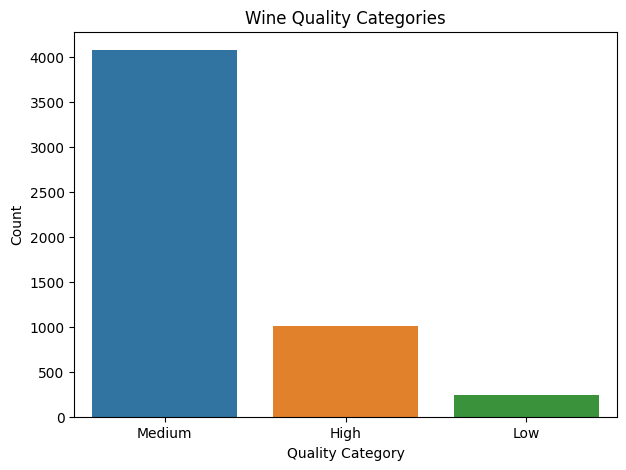

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=wine_data, x='quality_category', hue='quality_category')
plt.title('Wine Quality Categories')
plt.xlabel('Quality Category')
plt.ylabel('Count')
plt.show()

In [ ]:
X_class = wine_data.drop(['quality', 'quality_category'], axis=1)
y_class = wine_data['quality_category']

print("Features Shape:", X_class.shape)
print("Target Shape:", y_class.shape)

Features Shape: (5320, 12)
Target Shape: (5320,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class, y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Training Data:", X_train_class.shape)
print("Testing Data:", X_test_class.shape)

Training Data: (4256, 12)
Testing Data: (1064, 12)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_class = StandardScaler()

X_train_class_scaled = scaler_class.fit_transform(X_train_class)
X_test_class_scaled = scaler_class.transform(X_test_class)

print("Classification Feature Scaling Completed")

Classification Feature Scaling Completed


In [ ]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_class_scaled, y_train_class)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


In [ ]:
y_pred_log = log_model.predict(X_test_class_scaled)

print("Actual Values:")
print(y_test_class.head(10).values)

print("Predicted Values:")
print(y_pred_log[:10])

Actual Values:
['Medium' 'Medium' 'Medium' 'High' 'Medium' 'Medium' 'Low' 'Low' 'Medium'
 'Medium']
Predicted Values:
['Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'High'
 'Medium' 'Medium']


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test_class, y_pred_log)
precision = precision_score(y_test_class, y_pred_log, average='weighted')
recall = recall_score(y_test_class, y_pred_log, average='weighted')
f1 = f1_score(y_test_class, y_pred_log, average='weighted')

print("Logistic Regression Results")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Logistic Regression Results
Accuracy: 0.7678571428571429
Precision: 0.7309422047497421
Recall: 0.7678571428571429
F1 Score: 0.7303109749660484


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_class_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

dt_class_model.fit(X_train_class, y_train_class)

print("Decision Tree Classifier Trained Successfully")

Decision Tree Classifier Trained Successfully


In [ ]:
y_pred_dt_class = dt_class_model.predict(X_test_class)

print("Actual Values:")
print(y_test_class.head(10).values)

print("Predicted Values:")
print(y_pred_dt_class[:10])

Actual Values:
['Medium' 'Medium' 'Medium' 'High' 'Medium' 'Medium' 'Low' 'Low' 'Medium'
 'Medium']
Predicted Values:
['Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium'
 'Medium' 'Medium']


In [ ]:
accuracy_dt = accuracy_score(y_test_class, y_pred_dt_class)
precision_dt = precision_score(y_test_class, y_pred_dt_class, average='weighted')
recall_dt = recall_score(y_test_class, y_pred_dt_class, average='weighted')
f1_dt = f1_score(y_test_class, y_pred_dt_class, average='weighted')

print("Decision Tree Classification Results")
print("Accuracy:", accuracy_dt)
print("Precision:", precision_dt)
print("Recall:", recall_dt)
print("F1 Score:", f1_dt)

Decision Tree Classification Results
Accuracy: 0.7659774436090225
Precision: 0.7341409186044404
Recall: 0.7659774436090225
F1 Score: 0.7454851246695895


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_class_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_class_model.fit(X_train_class, y_train_class)

print("Random Forest Classifier Trained Successfully")

Random Forest Classifier Trained Successfully


In [ ]:
y_pred_rf_class = rf_class_model.predict(X_test_class)

print("Actual Values:")
print(y_test_class.head(10).values)

print("Predicted Values:")
print(y_pred_rf_class[:10])

Actual Values:
['Medium' 'Medium' 'Medium' 'High' 'Medium' 'Medium' 'Low' 'Low' 'Medium'
 'Medium']
Predicted Values:
['Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium'
 'Medium' 'Medium']


In [ ]:
accuracy_rf = accuracy_score(y_test_class, y_pred_rf_class)
precision_rf = precision_score(y_test_class, y_pred_rf_class, average='weighted')
recall_rf = recall_score(y_test_class, y_pred_rf_class, average='weighted')
f1_rf = f1_score(y_test_class, y_pred_rf_class, average='weighted')

print("Random Forest Classification Results")
print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1 Score:", f1_rf)

Random Forest Classification Results
Accuracy: 0.8007518796992481
Precision: 0.7943713736732113
Recall: 0.8007518796992481
F1 Score: 0.7734002086969682


In [ ]:
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf', C=10)

svm_model.fit(X_train_class_scaled, y_train_class)

print("SVM Model Trained Successfully")

SVM Model Trained Successfully


In [ ]:
y_pred_svm = svm_model.predict(X_test_class_scaled)

print("Actual Values:")
print(y_test_class.head(10).values)

print("Predicted Values:")
print(y_pred_svm[:10])

Actual Values:
['Medium' 'Medium' 'Medium' 'High' 'Medium' 'Medium' 'Low' 'Low' 'Medium'
 'Medium']
Predicted Values:
['Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium'
 'Medium' 'Medium']


In [ ]:
accuracy_svm = accuracy_score(y_test_class, y_pred_svm)
precision_svm = precision_score(y_test_class, y_pred_svm, average='weighted')
recall_svm = recall_score(y_test_class, y_pred_svm, average='weighted')
f1_svm = f1_score(y_test_class, y_pred_svm, average='weighted')

print("SVM Classification Results")
print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1 Score:", f1_svm)

SVM Classification Results
Accuracy: 0.7875939849624061
Precision: 0.7541193032393168
Recall: 0.7875939849624061
F1 Score: 0.7546044933388222


In [ ]:
classification_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM'],
    'Accuracy': [accuracy, accuracy_dt, accuracy_rf, accuracy_svm],
    'Precision': [precision, precision_dt, precision_rf, precision_svm],
    'Recall': [recall, recall_dt, recall_rf, recall_svm],
    'F1 Score': [f1, f1_dt, f1_rf, f1_svm]
})

print(classification_results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.767857   0.730942  0.767857  0.730311
1        Decision Tree  0.765977   0.734141  0.765977  0.745485
2        Random Forest  0.800752   0.794371  0.800752  0.773400
3                  SVM  0.787594   0.754119  0.787594  0.754604


In [ ]:
best_class_model = classification_results.loc[
    classification_results['F1 Score'].idxmax()
]

print("Best Classification Model:")
print(best_class_model)

Best Classification Model:
Model        Random Forest
Accuracy          0.800752
Precision         0.794371
Recall            0.800752
F1 Score            0.7734
Name: 2, dtype: object


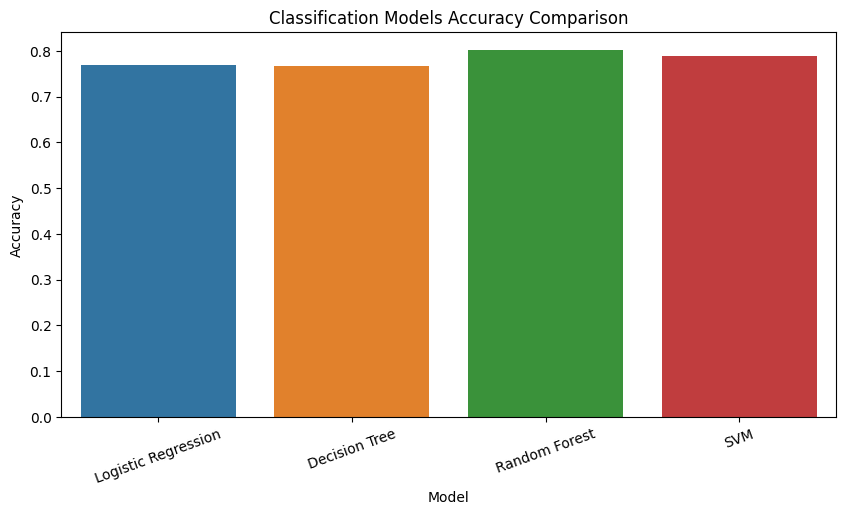

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=classification_results,
    x='Model',
    y='Accuracy',
    hue='Model',
    legend=False
)

plt.title('Classification Models Accuracy Comparison')
plt.xticks(rotation=20)
plt.show()

In [ ]:
model_predictions = {
    'Logistic Regression': y_pred_log,
    'Decision Tree': y_pred_dt_class,
    'Random Forest': y_pred_rf_class,
    'SVM': y_pred_svm
}

best_model_name = best_class_model['Model']
best_predictions = model_predictions[best_model_name]

print("Best Model:", best_model_name)

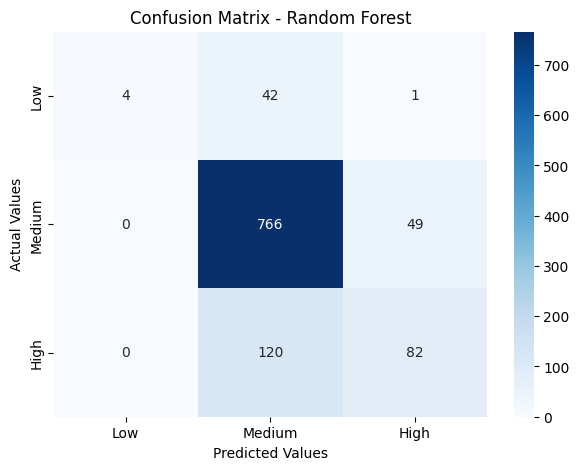

Best Model: Random Forest
              precision    recall  f1-score   support

        High       0.62      0.41      0.49       202
         Low       1.00      0.09      0.16        47
      Medium       0.83      0.94      0.88       815

    accuracy                           0.80      1064
   macro avg       0.82      0.48      0.51      1064
weighted avg       0.79      0.80      0.77      1064



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

model_predictions = {
    'Logistic Regression': y_pred_log,
    'Decision Tree': y_pred_dt_class,
    'Random Forest': y_pred_rf_class,
    'SVM': y_pred_svm
}

best_model_name = classification_results.loc[
    classification_results['F1 Score'].idxmax(), 'Model'
]

best_predictions = model_predictions[best_model_name]

cm = confusion_matrix(
    y_test_class,
    best_predictions,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title('Confusion Matrix - ' + best_model_name)
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

print("Best Model:", best_model_name)
print(classification_report(y_test_class, best_predictions))

In [ ]:
print("Classification Report:")
print(classification_report(y_test_class, best_predictions))

Classification Report:
              precision    recall  f1-score   support

        High       0.62      0.41      0.49       202
         Low       1.00      0.09      0.16        47
      Medium       0.83      0.94      0.88       815

    accuracy                           0.80      1064
   macro avg       0.82      0.48      0.51      1064
weighted avg       0.79      0.80      0.77      1064



In [ ]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                 Feature  Importance
10               alcohol    0.263777
1       volatile acidity    0.115381
5    free sulfur dioxide    0.094150
9              sulphates    0.083396
6   total sulfur dioxide    0.074483
8                     pH    0.070441
3         residual sugar    0.062588
4              chlorides    0.060620
0          fixed acidity    0.059187
7                density    0.058149
2            citric acid    0.056609
11             wine_type    0.001219


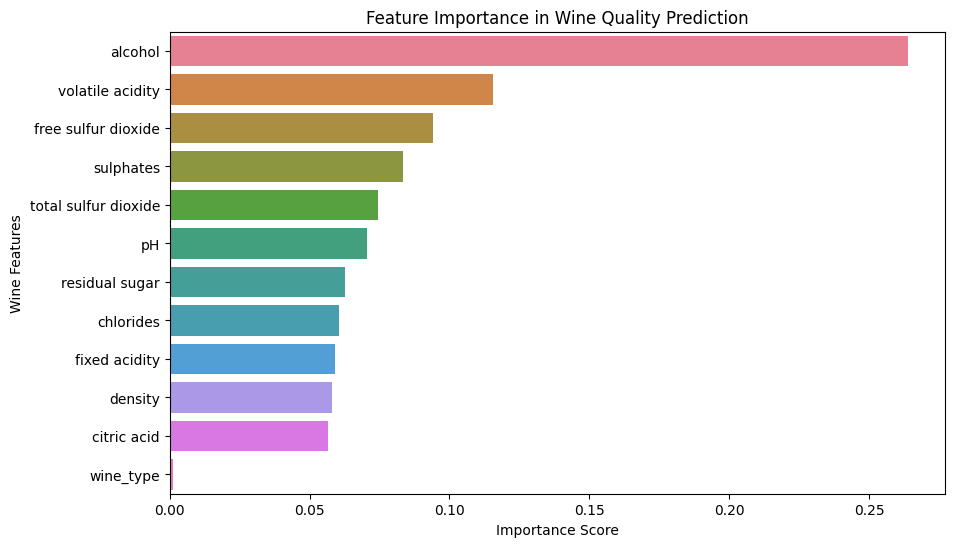

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    legend=False
)

plt.title('Feature Importance in Wine Quality Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Wine Features')
plt.show()

In [ ]:
print("Top 5 Important Features:")
print(feature_importance.head(5))

Top 5 Important Features:
                 Feature  Importance
10               alcohol    0.263777
1       volatile acidity    0.115381
5    free sulfur dioxide    0.094150
9              sulphates    0.083396
6   total sulfur dioxide    0.074483


In [ ]:
new_wine = X_test.iloc[[0]]

predicted_quality = rf_model.predict(new_wine)

print("Wine Chemical Properties:")
print(new_wine)

print("Predicted Wine Quality:", round(predicted_quality[0], 2))
print("Actual Wine Quality:", y_test.iloc[0])

Wine Chemical Properties:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
1878            5.3              0.32         0.12             6.6      0.043   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
1878                 22.0                 141.0   0.9937  3.36        0.6   

      alcohol  wine_type  
1878     10.4          1  
Predicted Wine Quality: 5.69
Actual Wine Quality: 6


In [ ]:
new_wine_class = X_test_class.iloc[[0]]

predicted_category = rf_class_model.predict(new_wine_class)

print("Predicted Wine Category:", predicted_category[0])
print("Actual Wine Category:", y_test_class.iloc[0])

Predicted Wine Category: Medium
Actual Wine Category: Medium


In [ ]:
print("FINAL WINE QUALITY PREDICTION")
print("--------------------------------")
print("Regression Prediction:", round(predicted_quality[0], 2))
print("Classification Prediction:", predicted_category[0])


FINAL WINE QUALITY PREDICTION
--------------------------------
Regression Prediction: 5.69
Classification Prediction: Medium


### 6. Project Summary & Key Findings

- **Data Profile**: Combining the datasets yielded **5,320 unique records** (1,359 Red, 3,961 White) after duplicate removal.
- **Top Features**: Feature importance from the Random Forest Model confirmed that **alcohol** ($≈ 26.4\%$) and **volatile acidity** ($≈ 11.5\%$) are the most critical physicochemical properties influencing quality.
- **Regression Performance**: **Random Forest Regressor** outperformed other models with the lowest MAE (**0.51**) and the highest $R^2$ Score (**0.41**).
- **Classification Performance**: Discretizing the targets into three classes (Low, Medium, High) allowed the **Random Forest Classifier** to achieve **80% Accuracy** and a weighted **F1-score of 0.77**.